In [21]:
try:
  import cellpylib as cpl
except:
  print('Installing cellpylib ...')
  !pip install cellpylib
  import cellpylib as cpl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import json
from sys import getsizeof

In [2]:
# uncomment if you want to use Drive

from google.colab import drive
drive.mount('/content/gdrive')#, force_remount=True)
#

# images_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Images'
# models_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Models'
files_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Files'

# Show available files
!ls '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Files'

Mounted at /content/gdrive
all_Li-Packard_dict.json
ECAs_1024sims-per-rule_64x64_train_diagrams_noise-type-missing_noise-level-0p05_on-both.npy
ECAs_1024sims-per-rule_64x64_train_diagrams_noise-type-missing_noise-level-0p15_on-both.npy
ECAs_1024sims-per-rule_64x64_train_diagrams_noise-type-missing_noise-level-0p1_on-both.npy
ECAs_1024sims-per-rule_64x64_train_diagrams_noise-type-missing_noise-level-0p25_on-both.npy
ECAs_1024sims-per-rule_64x64_train_diagrams_noise-type-missing_noise-level-0p2_on-both.npy
ECAs_1024sims-per-rule_64x64_train_diagrams_noise-type-missing_noise-level-0p35_on-both.npy
ECAs_1024sims-per-rule_64x64_train_diagrams_noise-type-missing_noise-level-0p3_on-both.npy
ECAs_1024sims-per-rule_64x64_train_diagrams_noise-type-missing_noise-level-0p45_on-both.npy
ECAs_1024sims-per-rule_64x64_train_diagrams_noise-type-missing_noise-level-0p4_on-both.npy
ECAs_1024sims-per-rule_64x64_train_diagrams_noise-type-missing_noise-level-0p5_on-both.npy
ECAs_1024sims-per-rule_64x64_trai

# Intention and current state

In this Notebook we want to create an environment for easily generating a dataset of spacetime diagrams of various dimensions, initial conditions, and setups, with the corresponding labels. Currently we have a database for:
1. Reproducing the Silverman 2019 dataset: training: 32768 spacetime diagrams of size 120 x 60 from ECAs. For test: 4096 new spacetime diagrams.
2. 32768 spacetime diagrams of size 64 x 64 from ECAs, with 128 random initialisation per label (Wolfram rule 0 to 255). For test: 16 simulations per rule.
3. 262144 spacetime diagrams of size 64 x 64 from ECAs, with 1024 random initialisation per label (Wolfram rule 0 to 255). For test: 128 simulations per rule.
4. 32768 spacetime diagrams of size 112 x 112 from ECAs, with 128 simulations per rule. For test: 16 simulations per rule.

**Questions**
1. Should I create an equal number of samples per class or per rule? Or take out the equivalent rules? Probably per rule, and then I can weigh them differently afterwards, if needed.
2. All spacetime diagrams (so far) consist of integers. Is it wise to save them as such? I saved them as int8 and int16, but this can definitely be better still.

# Elementary Cellular Automata

## Li-Packard classes

In [ ]:
# Copy list of equivalent rules from Li-Packard (1990) p. 286
# Save once

SAVE_EQUIV_DICT = False

equiv_dict = dict({
  0: [255],
  1: [127],
  2: [16,191,247],
  3: [17,63,119],
  4: [223],
  5: [95],
  6: [20,159,215],
  7: [21,31 ,87],
  8: [64,239,253],
  9: [65,111 ,125],
  10: [80,175,245],
  11: [47,81,117],
  12: [68,207,221],
  13: [69,79,93],
  14: [84,143,213],
  15: [85],
  18: [183],
  19: [55],
  22: [151],
  23: [],
  24: [66,189,231],
  25: [61,67,103],
  26: [82,167,181],
  27: [39,53,83],
  28: [70,157,199],
  29: [71],
  30: [86,135,149],
  32: [251],
  33: [123],
  34: [48,187,243],
  35: [49,59,115],
  36: [219],
  37: [91],
  38: [52,155,211],
  40: [96,235,249],
  41: [97,107,121],
  42: [112,171,241],
  43: [113],
  44: [100,203,217],
  45: [75,89,101],
  46: [116,139,209],
  50: [179],
  51: [],
  54: [147],
  56: [98,185,227],
  57: [99],
  58: [114,163,177],
  60: [102,153,195],
  72: [237],
  73: [109],
  74: [88,173,229],
  76: [205],
  77: [],
  78: [92,141,197],
  90: [165],
  104: [233],
  105: [],
  106: [120,169,225],
  108: [201],
  128: [254],
  129: [126],
  130: [144,190,246],
  131: [62,145,118],
  132: [222],
  133: [94],
  134: [148,158,214],
  136: [192,238,252],
  137: [110,124,193],
  138: [174,208,244],
  140: [196,206,220],
  142: [212],
  146: [182],
  150: [],
  152: [188,194,230],
  154: [166,180,210],
  156: [198],
  160: [250],
  161: [122],
  162: [176,186,242],
  164: [218],
  168: [224,234,248],
  170: [240],
  172: [202,216,228],
  178: [],
  184: [226],
  200: [236],
  204: [],
  232: []
})

if SAVE_EQUIV_DICT:
  # create json object from dictionary
  output = json.dumps(equiv_dict)

  # open file for writing, "w" 
  f = open(f"{files_dir}/equiv_ECA_rules.json","w")

  # write json object to file
  f.write(output)

  # close file
  f.close()

  print("Dictionary has been saved as json")

In [ ]:
# Create dict that translates non-equivalent rule to Li-Packard class
# Save once

SAVE_NONEQUIV_LP_DICT = False

# Copy list of non-equivalent ECA rules from Li-Packard (1990) page 288

null = [0, 8, 32, 40, 128, 136, 160, 168]
fixed_point = [2, 4, 10, 12, 13, 24, 34, 36, 42, 44, 46, 56, 57, 58, 72, 76, 77, 78, 104, 130, 132, 138, 140, 152, 162, 164, 170, 172, 184, 200, 204, 232]
periodic = [1, 3, 5, 6, 7, 9, 11, 14, 15, 19,23, 25, 27,28, 29,33, 35,37, 38, 41, 43, 50, 51, 74, 108, 131, 133, 134, 142, 156, 178]
locally_chaotic = [26, 73, 154]
chaotic = [18, 22, 30, 45, 54, 60, 90, 105, 106, 129, 137, 146, 150, 161]

partial_lp_dict = dict({
    'null' : null,
    'fixed point' : fixed_point,
    'periodic' : periodic,
    'locally chaotic' : locally_chaotic,
    'chaotic' : chaotic
})

if SAVE_NONEQUIV_LP_DICT:
  # create json object from dictionary
  output = json.dumps(partial_lp_dict)

  # open file for writing, "w" 
  f = open(f"{files_dir}/nonequiv_Li-Packard_dict.json","w")

  # write json object to file
  f.write(output)

  # close file
  f.close()

  print("Dictionary has been saved as json")

In [ ]:
# Create dict that links any rule to Li-Packard class
# Save once

SAVE_ALL_LP_DICT = False

all_null = null.copy()
all_fixed_point = fixed_point.copy()
all_periodic = periodic.copy()
all_locally_chaotic = locally_chaotic.copy()
all_chaotic = chaotic.copy()
for lp_class in [all_null, all_fixed_point, all_periodic, all_locally_chaotic, all_chaotic]:
  rules=[]
  for rule in lp_class:
    equiv_rules = equiv_dict[rule]
    rules += equiv_rules
  lp_class += rules
  lp_class.sort()

# Sanity check
all_rules = all_null + all_fixed_point + all_periodic + all_locally_chaotic + all_chaotic
total_number_of_rules = len(all_rules)
total_number_unique_rules = len(set(all_rules))
print(f"{total_number_of_rules} have been distributed, {total_number_unique_rules} of which are unique.\n")

all_lp_dict = dict({
    'null' : all_null,
    'fixed point' : all_fixed_point,
    'periodic' : all_periodic,
    'locally chaotic' : all_locally_chaotic,
    'chaotic' : all_chaotic
})

for key, item in all_lp_dict.items():
  print(f"Class '{key}' contains {len(item)} rules.")

if SAVE_ALL_LP_DICT:
  # create json object from dictionary
  output = json.dumps(all_lp_dict)

  # open file for writing, "w" 
  f = open(f"{files_dir}/all_Li-Packard_dict.json","w")

  # write json object to file
  f.write(output)

  # close file
  f.close()

  print("Dictionary has been saved as json")

256 have been distributed, 256 of which are unique.

Class 'null' contains 24 rules.
Class 'fixed point' contains 97 rules.
Class 'periodic' contains 89 rules.
Class 'locally chaotic' contains 10 rules.
Class 'chaotic' contains 36 rules.


In [ ]:
# PREVIOUS CLASSIFICATION, BUT NOT TRUE TO PAPER

# null = [0, 255, 8, 64, 239, 253, 32, 251, 40, 96, 235, 249, 128, 254, 136,
#                        192, 238, 252, 160, 250, 168, 224, 234, 248]
# fixed_point = [2, 16, 191, 247, 4, 223, 10, 80, 175, 245, 12, 68, 207, 221,
#                               13, 69, 79, 93, 24, 66, 189, 231, 34, 48, 187, 243, 36 , 219,
#                               42, 112, 171, 241, 44, 100, 203, 217, 46, 116, 139, 209, 56, 
#                               98, 185, 227, 57, 99, 58, 114, 163, 177, 72, 237, 76, 205, 77,
#                               78, 92, 141, 197, 104, 233, 130, 144, 190, 246, 132, 222, 138, 
#                               174, 208, 244, 140, 196, 206, 220, 152, 188, 194, 230, 162, 176,
#                               186, 242, 164, 218, 170, 240, 172, 202, 216, 228, 184, 226, 200, 
#                               236, 204, 232]
# two_cycle = [1, 127, 3, 17, 63, 119, 5, 95, 6, 20, 159, 215, 7, 21, 31, 87, 9,
#                             65, 111, 125, 11, 47, 81, 117, 14, 84, 143, 213, 15, 85, 19, 55, 23, 25,
#                             61, 67, 103, 27, 28, 70, 157, 199, 39, 53, 83, 29, 71, 33, 123, 35, 49, 59, 115, 37, 
#                             91, 38, 52, 155, 211, 43, 113, 50, 179, 51, 74, 88, 173, 229, 108,
#                             201, 134, 148, 158, 214, 142, 212, 156, 198, 178]
# periodic = [26, 82, 167, 181, 41, 97, 107, 121, 62, 118, 131, 145, 94, 133, 154, 
#                            166, 180, 210]
# compleks = [54, 147, 110, 124, 137, 193]
# chaotic = [18, 183, 22, 151, 30, 86, 135, 149, 45, 75, 89, 101, 60, 102, 153, 195,
#                           73, 109, 90, 165, 105, 106, 120, 169, 225, 122, 161, 126, 129, 146, 182, 150]

# # Sort all lists
# null.sort(); fixed_point.sort(); two_cycle.sort(); periodic.sort(); compleks.sort(); chaotic.sort()

# LiPackardDict = dict({'Null' : null,
#                       'Fixed Point' : fixed_point,
#                       'Two-Cycle' : two_cycle,
#                       'Periodic' : periodic,
#                       'Complex' : compleks,
#                       'Chaotic' : chaotic})

# if SAVE_DICT:
#   # create json object from dictionary
#   output = json.dumps(LiPackardDict)

#   # open file for writing, "w" 
#   f = open(f"{files_dir}/Li_Packard_dict.json","w")

#   # write json object to file
#   f.write(output)

#   # close file
#   f.close()

## Spacetime Diagrams

In [59]:
LOOP_AGAIN = True
SAVE = True

# Choose width (spatial) and length (temporal) features of spacetime diagram
WIDTH = 112
LENGTH = 112

# Choose total number of simulations, ideally a multiple of the number of rules
NRULES = 256
NSIM_PER_RULE_TRAIN = 128
NSIM_PER_RULE_TEST = 16
NSIM_TRAIN = NRULES * NSIM_PER_RULE_TRAIN
NSIM_TEST = NRULES * NSIM_PER_RULE_TEST

# General save name
save_name_train = f"ECAs_{NSIM_PER_RULE_TRAIN}sims-per-rule_{WIDTH}x{LENGTH}_train"
save_name_test = f"ECAs_{NSIM_PER_RULE_TEST}sims-per-rule_{WIDTH}x{LENGTH}_test"


if LOOP_AGAIN:

  # Allocate empty numpy array with the desired dimensions for tensorflow,
  # including the final channel dimension (1)
  all_diagrams_train = np.empty((NSIM_TRAIN, LENGTH, WIDTH, 1), dtype=np.ubyte)
  all_labels_train = np.empty((NSIM_TRAIN, 1), dtype=np.uint8)
  all_diagrams_test = np.empty((NSIM_TEST, LENGTH, WIDTH, 1), dtype=np.ubyte)
  all_labels_test = np.empty((NSIM_TEST, 1), dtype=np.uint8)

  # Loop over every NKS rule, take random initial condition every time
  for rule in range(NRULES):
    print(f"\rWorking on rule {rule}/{NRULES-1}.", end='') # strange construction but works
    for sim in range(NSIM_PER_RULE_TRAIN):
      init_config = cpl.init_random(WIDTH)
      # Evolve rule over CA
      diagram = cpl.evolve(init_config, timesteps=LENGTH, memoize=True, 
                  apply_rule=lambda n, c, t: cpl.nks_rule(n, rule), r=1)
      iter = rule*NSIM_PER_RULE_TRAIN + sim
      all_diagrams_train[iter, :, :, 0] = diagram
      all_labels_train[iter, 0] = np.array([rule])
    for sim in range(NSIM_PER_RULE_TEST):
      init_config = cpl.init_random(WIDTH)
      # Evolve rule over CA
      diagram = cpl.evolve(init_config, timesteps=LENGTH, memoize=True, 
                  apply_rule=lambda n, c, t: cpl.nks_rule(n, rule), r=1)
      iter = rule*NSIM_PER_RULE_TEST + sim
      all_diagrams_test[iter, :, :, 0] = diagram
      all_labels_test[iter, 0] = np.array([rule])

  if SAVE:
    # Save results in .npy file
    with open(f"{files_dir}/{save_name_train}_diagrams.npy", 'wb') as f:
      np.save(f, all_diagrams_train)
    with open(f"{files_dir}/{save_name_train}_labels.npy", 'wb') as f:
      np.save(f, all_labels_train)
    with open(f"{files_dir}/{save_name_test}_diagrams.npy", 'wb') as f:
      np.save(f, all_diagrams_test)
    with open(f"{files_dir}/{save_name_test}_labels.npy", 'wb') as f:
      np.save(f, all_labels_test)

else:
  all_diagrams_train = np.load(f"{files_dir}/{save_name_train}_diagrams.npy")
  all_labels_train = np.load(f"{files_dir}/{save_name_train}_labels.npy")
  all_diagrams_test = np.load(f"{files_dir}/{save_name_test}_diagrams.npy")
  all_labels_test = np.load(f"{files_dir}/{save_name_test}_labels.npy")

Working on rule 255/255.

In [58]:
original_size = getsizeof(all_diagrams_train)
new_size = getsizeof(np.ubyte(all_diagrams_train))

new_size / original_size

1.0

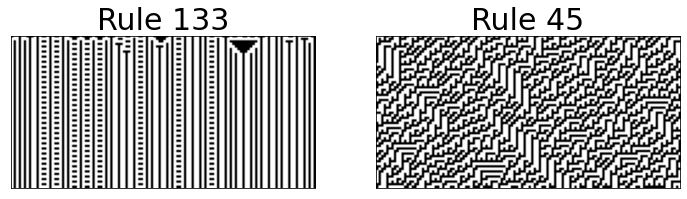

In [ ]:
# Show a couple results
number_of_examples = 2 # not more than five
examples_indices = np.random.choice(range(NSIM_TRAIN), number_of_examples, replace=False)
fig, axs = plt.subplots(1,number_of_examples, figsize=(6*WIDTH/LENGTH, 6*number_of_examples))
for i, ex in enumerate(examples_indices):
  axs[i].imshow(all_diagrams_train[ex, :, :, 0], cmap='Greys')
  axs[i].set_title(f"Rule {all_labels_train[ex,0]}", size=30)
  axs[i].set_xticks([])
  axs[i].set_yticks([])

plt.savefig(f"{files_dir}/example_spacetime_diagram.pdf", bbox_inches='tight')

## Noisy spacetime diagrams

In [3]:
def add_noise(diagrams, noise_level=0, dim='both', noise_type='missing', return_mask=False):
    """
    Function that adds noise to a particular CA spacetime diagram
    
    Inputs
    ------
    diagram : np.array. the CA spacetime diagram
    
    noise_level : float. Value between 0 and 1 (including boundaries). Fraction of cells that are affected.
        Will round to closest possibility. Example: noise_level of 0.06 with dim='Time' for a CA diagram with
        only 10 timesteps will round to one timestep being affected by the noise.
    
    dim : str. Dimension on which the noise applies. Choose between ...
        'space': Particular cells are continuously affected by the noise
        'time': Entire time steps are affected by the noise
        'both': (default) A fraction {noise_level} of all pixels in the spacetime diagram are given noise randomly
        
    noise_type : str. Choose between ...
        'missing': (default) Add -1 values as noise
        'wrong': Switch a 0 to a 1 and vice versa
        
    return_mask : bool. If True, return the np.array with boolean values (True where pixels have been affected by noise)
        
    Output
    ------
    noise_diagram : np.array. Same diagram as the input, but with added noise.
    
    noise_mask : np.array. Matrix with Booleans and same size as noise_diagram. True where pixels have been affected.
    """
    
    if noise_level < 0 or noise_level > 1:
        raise Exception(f"A noise_level fraction of {noise_level} has no meaning. Choose a value between 0 and 1.")
        
    if dim not in ['space', 'time', 'both']:
        raise Exception("Parameter dim should be 'space', 'time', or 'both'.")
        
    if noise_type not in ['missing', 'wrong']:
        raise Exception("Parameter noise_type should be 'missing' or 'wrong'.")
        
    noise_diagrams = diagrams.copy()
    N = noise_diagrams.shape[0]
    timesteps = noise_diagrams.shape[1]
    size = noise_diagrams.shape[2]

    noise_masks = []
    
    if dim == 'both':
        affected_cells = round(noise_level*timesteps*size)
        unaffected_cells = timesteps*size - affected_cells
        for n in range(N):
          noise_mask = np.random.permutation([True]*affected_cells+[False]*unaffected_cells)
          noise_mask = np.reshape(noise_mask, (timesteps,size,1))
          noise_masks.append(noise_mask)
    elif dim == 'time':
        affected_cells = round(noise_level*timesteps)
        unaffected_cells = timesteps - affected_cells
        for n in range(N):
          noise_mask = np.array([np.random.permutation([True]*affected_cells+[False]*unaffected_cells)])
          noise_mask = np.expand_dims(np.tile(noise_mask.T, (1,size)), axis=2)
          noise_masks.append(noise_mask)
    elif dim == 'space':
        affected_cells = round(noise_level*size)
        unaffected_cells = size - affected_cells
        for n in range(N):
          noise_mask = np.array([np.random.permutation([True]*affected_cells+[False]*unaffected_cells)])
          noise_mask = np.expand_dims(np.tile(noise_mask, (timesteps,1)), axis=2)
          noise_masks.append(noise_mask)
        
    noise_masks = np.array(noise_masks)
    if noise_type == 'missing':
        noise_diagrams[noise_masks] = -1
    elif noise_type == 'wrong':
        noise_diagrams[noise_masks] = 1-noise_diagrams[noise_masks] # bit-switch
        
    if return_mask:
        return noise_diagrams, noise_masks
    return noise_diagrams

In [4]:
train_name_prefix = "ECAs_1024sims-per-rule_64x64"
train_diagram_name = train_name_prefix + "_train_diagrams.npy"
train_label_name = train_name_prefix + "_train_labels.npy"

test_name_prefix = "ECAs_128sims-per-rule_64x64"
test_diagram_name = test_name_prefix + "_test_diagrams.npy"
test_label_name = test_name_prefix + "_test_labels.npy"

x_train_all = np.load(f"{files_dir}/{train_diagram_name}")
r_train_rule_all = np.load(f"{files_dir}/{train_label_name}")
x_test_all = np.load(f"{files_dir}/{test_diagram_name}")
r_test_rule_all = np.load(f"{files_dir}/{test_label_name}")

FileNotFoundError: ignored

In [ ]:
SAVE = True

noise_type = 'wrong'
dim = 'both'
noise_levels = [0.35, 0.40, 0.45, 0.50] # [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]

for noise_level in noise_levels:
  print(f"Working on noise level {noise_level}.")

  train_name = train_diagram_name[:-4] + '_noise-type-' + noise_type + '_noise-level-' + str(noise_level).replace('.', 'p') + '_on-' + dim + '.npy'
  test_name = test_diagram_name[:-4] + '_noise-type-' + noise_type + '_noise-level-' + str(noise_level).replace('.', 'p') + '_on-' + dim + '.npy'

  x_train_all_noise = add_noise(x_train_all, noise_level=noise_level, dim=dim, noise_type=noise_type)
  x_test_all_noise = add_noise(x_test_all, noise_level=noise_level, dim=dim, noise_type=noise_type)

  if SAVE:
    # Save results in .npy file
    with open(f"{files_dir}/{train_name}", 'wb') as f:
      np.save(f, x_train_all_noise)
      print(f"Saved {train_name}.")
    with open(f"{files_dir}/{test_name}", 'wb') as f:
      np.save(f, x_test_all_noise)
      print(f"Saved {test_name}.")

  del x_train_all_noise
  del x_test_all_noise

Working on noise level 0.35.
Saved ECAs_1024sims-per-rule_64x64_train_diagrams_noise-type-wrong_noise-level-0p35_on-both.npy.
Saved ECAs_128sims-per-rule_64x64_test_diagrams_noise-type-wrong_noise-level-0p35_on-both.npy.
Working on noise level 0.4.
Saved ECAs_1024sims-per-rule_64x64_train_diagrams_noise-type-wrong_noise-level-0p4_on-both.npy.
Saved ECAs_128sims-per-rule_64x64_test_diagrams_noise-type-wrong_noise-level-0p4_on-both.npy.
Working on noise level 0.45.
Saved ECAs_1024sims-per-rule_64x64_train_diagrams_noise-type-wrong_noise-level-0p45_on-both.npy.
Saved ECAs_128sims-per-rule_64x64_test_diagrams_noise-type-wrong_noise-level-0p45_on-both.npy.
Working on noise level 0.5.
Saved ECAs_1024sims-per-rule_64x64_train_diagrams_noise-type-wrong_noise-level-0p5_on-both.npy.
Saved ECAs_128sims-per-rule_64x64_test_diagrams_noise-type-wrong_noise-level-0p5_on-both.npy.
